# Currency clusters through time: R2K audit and neural handoff

**TA priority: observed temporal evolution, genuine five-year co-clustering windows, and paper-level implementation verification.**

R2K updates continuously according to Algorithm 2. Its 12-month FX-feature lookback, centroid memory W=1/6/12, and 60-month co-clustering reporting window have distinct roles. Compare K=2–6, pair frequencies, coverage, group sizes and partition agreement over 1/12/60 months. A separate NumPy replay checks 135 post-initialization updates against the production algorithm; remaining implementation conventions and paper claims are disclosed.

This descriptive analysis uses the available 1994–August 2026 panel, including previously inspected post-2019 data. It is not forecast validation. The earlier 2011–2019 frozen-group comparison and synchronized neural datasets remain below as the teammate handoff; dynamic labels never silently change currency channels.

Install `python -m pip install -e ".[clustering,reports,dev]"`, select that kernel, and run all cells from the repository root or `notebooks/`. Saved results are hash-verified before reuse. The primary command remains `python scripts/build_clustering_handoff.py`.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "config/research_sample.json").is_file()
             and (p / "src/fx_forecasting").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the repository checkout.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from fx_forecasting.evaluation.clustering_handoff import build_clustering_handoff, sha256
from fx_forecasting.data.neural_dataset import load_cluster_dataset
OUTPUT = ROOT / "reports/clustering/handoff"
REBUILD = False

In [2]:
def verified_outputs():
    path = OUTPUT / "manifest.json"
    if not path.is_file():
        return False
    try:
        manifest = json.loads(path.read_text())
        sources = {"observations.parquet": ROOT / "data/ingested/observations.parquet",
                   "research_sample.json": ROOT / "config/research_sample.json",
                   "clustering_handoff.json": ROOT / "config/clustering_handoff.json"}
        if not manifest["include_dtw"] or manifest["settings"]["bootstrap_reps"] != 50:
            return False
        if not {"clustering_report.pdf", "clustering_report.html", "group_quality.csv",
                "factor_reference.csv", "bootstrap_coassignment.npz", "evolution_labels.npz",
                "evolution_summary.csv", "evolution_initialization.csv"}.issubset(manifest["outputs"]):
            return False
        return (all(sha256(path) == manifest["source_sha256"][name] for name, path in sources.items())
                and all(sha256(ROOT / name) == digest for name, digest in manifest["implementation_sha256"].items())
                and all(sha256(OUTPUT / name) == digest for name, digest in manifest["outputs"].items()))
    except (KeyError, OSError, ValueError):
        return False

if REBUILD or not verified_outputs():
    manifest = build_clustering_handoff(output_dir=OUTPUT)
else:
    manifest = json.loads((OUTPUT / "manifest.json").read_text())
print("Verified outputs:", len(manifest["outputs"]))
print("Local tensor:", manifest["array_shapes"]["X_local"], "| targets:", manifest["array_shapes"]["Y"])

Verified outputs: 36
Local tensor: [381, 12, 39, 7] | targets: [381, 39, 3]


## 0. Observed evolution and the R2K implementation audit

Start with the [interactive five-year explorer](../reports/clustering/handoff/clustering_report.html#evolution). R2K is continuous; the correlation references refit 60-month return histories. Pair frequencies use only jointly eligible months. ARIs at longer lags and group-size diagnostics help separate short-run continuity, overlapping-window smoothness and a large catch-all group. Post-2019 observations are descriptive.


Continuous state initialization: 1995-01
Comparable summary endpoints: 2015-07 to 2026-08


,method,k,months,mean_assets,mean_ari_1m,mean_ari_12m,mean_ari_60m,mean_switch_rate,mean_largest_share,mean_effective_groups,mean_singleton_fraction,mean_pair_together
1,adjusted_average,3,134,38.993,0.875,0.659,0.400,0.052,0.381,2.946,0.000,0.328
6,r2k_w1,3,134,38.993,0.757,0.262,0.160,0.083,0.723,1.990,0.018,0.603
11,r2k_w12,3,134,38.993,0.719,0.230,0.131,0.090,0.646,2.199,0.011,0.523
16,r2k_w6,3,134,38.993,0.728,0.259,0.143,0.087,0.677,2.120,0.014,0.555
21,returns_average,3,134,38.993,0.935,0.798,0.399,0.010,0.930,1.349,0.033,0.865


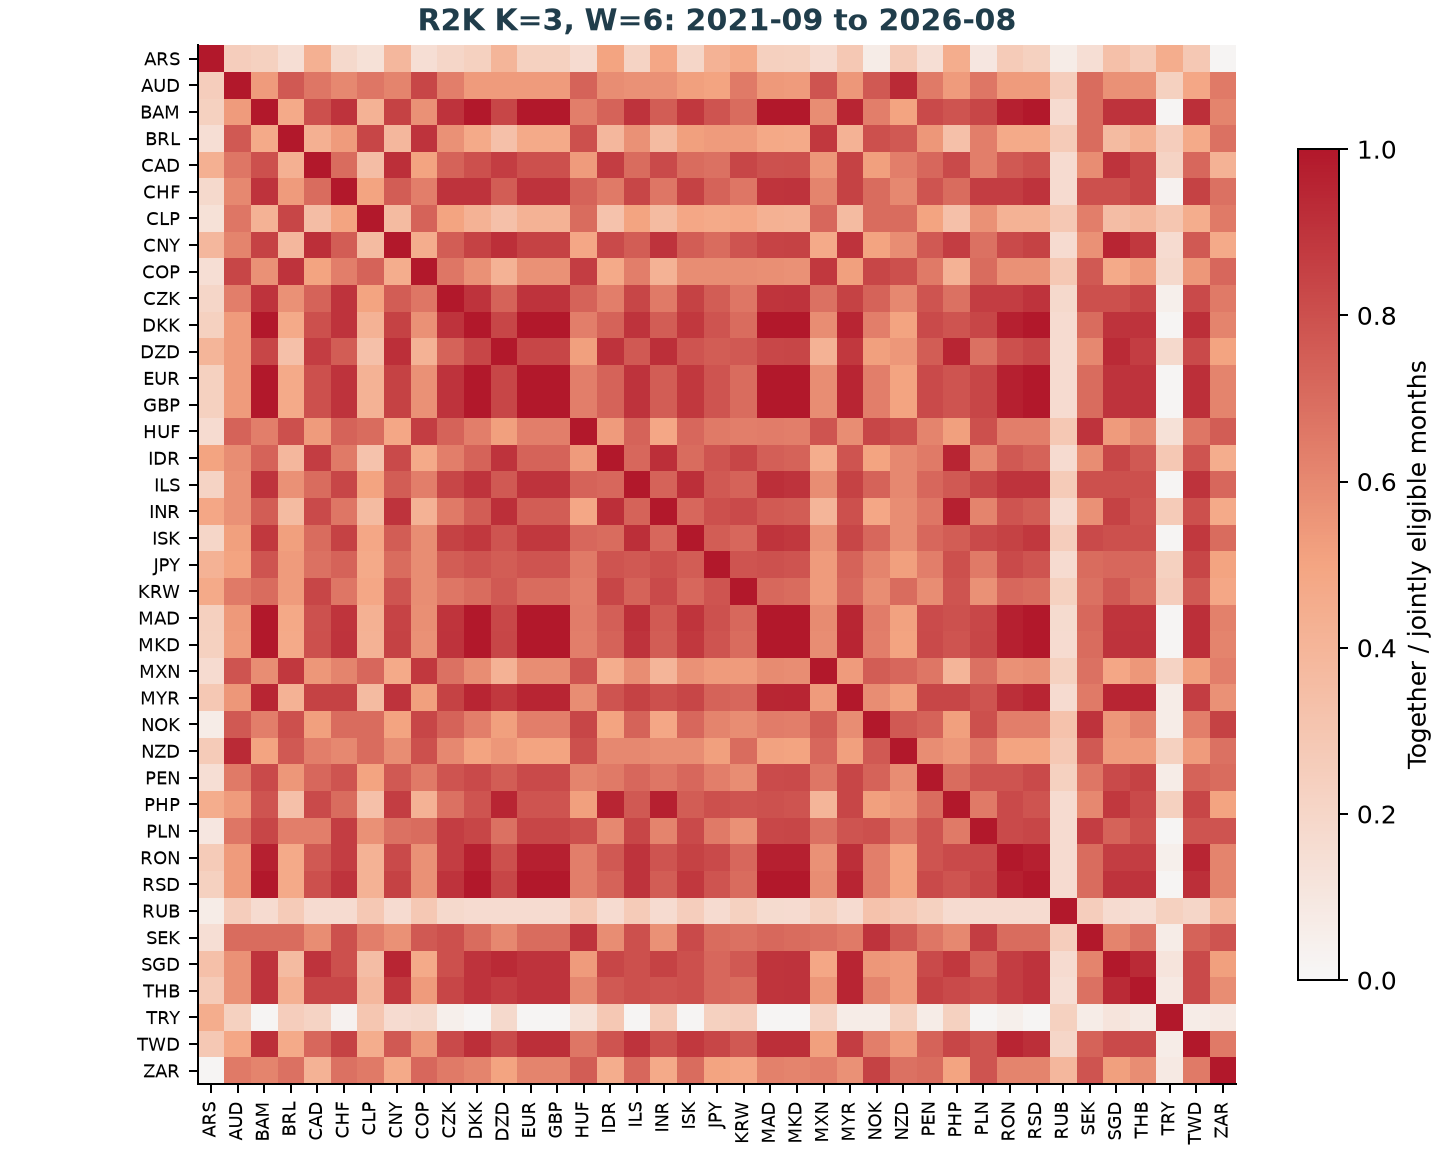

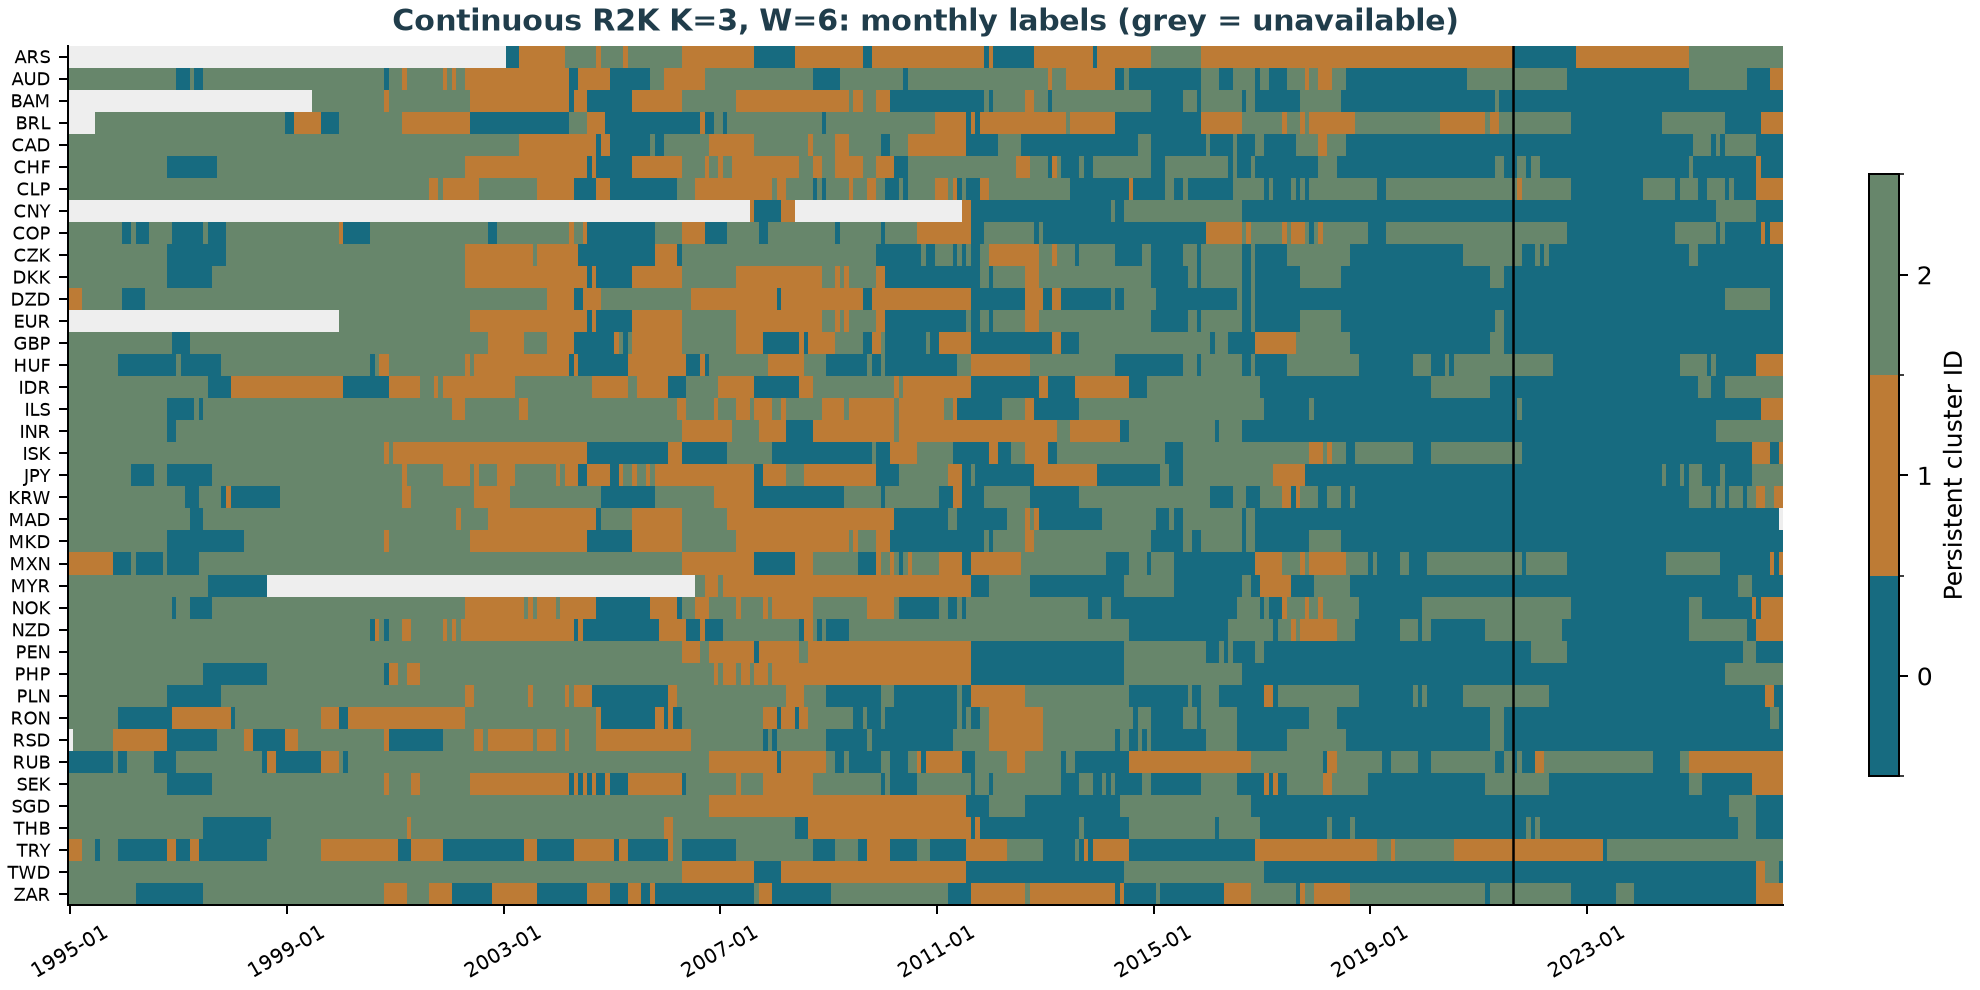

In [3]:
from fx_forecasting.evaluation.clustering_evolution import pair_frequencies

evolution_metadata = json.loads((OUTPUT / "evolution_metadata.json").read_text())
evolution_summary = pd.read_csv(OUTPUT / "evolution_summary.csv")
print("Continuous state initialization:", evolution_metadata["initialization"])
print("Comparable summary endpoints:", evolution_metadata["summary_start"], "to", evolution_metadata["summary_end"])
display(evolution_summary.loc[evolution_summary.k.eq(3)].round(3))
display(Image(filename=str(OUTPUT / "evolution_coclustering.png")))
display(Image(filename=str(OUTPUT / "evolution_memberships.png")))


In [4]:
# Exact five-year numerator and eligibility denominator, with stable currency order.
with np.load(OUTPUT / "evolution_labels.npz", allow_pickle=False) as temporal:
    path = temporal["r2k_w6:k3"]
together, observed = pair_frequencies(path[-60:])
frequencies = np.divide(together[-1], observed[-1],
                        out=np.full(together.shape[1:], np.nan), where=observed[-1] > 0)
currencies = evolution_metadata["currencies"]
print("Latest 60-month interval:", evolution_metadata["dates"][-60], "to", evolution_metadata["dates"][-1])
display(pd.DataFrame(frequencies, index=currencies, columns=currencies).round(2))
initialization_audit = pd.read_csv(OUTPUT / "evolution_initialization.csv")
display(initialization_audit.groupby(["kind", "n_init", "seed"]).ari_to_continuous.agg(["count", "mean", "min"]))
print("Independent Algorithm 2 replay: tests/test_r2k_paper_reference.py")


Latest 60-month interval: 2021-09 to 2026-08


,ARS,AUD,BAM,BRL,CAD,CHF,CLP,CNY,COP,CZK,...,PLN,RON,RSD,RUB,SEK,SGD,THB,TRY,TWD,ZAR
ARS,1.00,0.25,0.23,0.15,0.43,0.18,0.13,0.38,0.15,0.20,...,0.10,0.27,0.23,0.07,0.15,0.33,0.27,0.45,0.28,0.02
AUD,0.25,1.00,0.53,0.77,0.67,0.60,0.67,0.62,0.83,0.63,...,0.67,0.53,0.53,0.25,0.70,0.57,0.57,0.23,0.48,0.65
BAM,0.23,0.53,1.00,0.47,0.80,0.90,0.42,0.85,0.57,0.90,...,0.83,0.97,1.00,0.17,0.70,0.90,0.90,0.02,0.92,0.62
BRL,0.15,0.77,0.47,1.00,0.43,0.53,0.83,0.38,0.90,0.57,...,0.63,0.47,0.47,0.27,0.70,0.37,0.43,0.25,0.47,0.68
CAD,0.43,0.67,0.80,0.43,1.00,0.70,0.35,0.92,0.50,0.73,...,0.63,0.77,0.80,0.17,0.58,0.90,0.83,0.22,0.72,0.42
CHF,0.18,0.60,0.90,0.53,0.70,1.00,0.50,0.75,0.63,0.90,...,0.87,0.87,0.90,0.17,0.80,0.80,0.83,0.03,0.85,0.68
CLP,0.13,0.67,0.42,0.83,0.35,0.50,1.00,0.37,0.73,0.50,...,0.57,0.42,0.42,0.28,0.63,0.35,0.38,0.30,0.45,0.65
CNY,0.38,0.62,0.85,0.38,0.92,0.75,0.37,1.00,0.45,0.75,...,0.68,0.82,0.85,0.17,0.57,0.95,0.88,0.17,0.77,0.47
COP,0.15,0.83,0.57,0.90,0.50,0.63,0.73,0.45,1.00,0.67,...,0.70,0.57,0.57,0.28,0.77,0.47,0.53,0.18,0.55,0.72
CZK,0.20,0.63,0.90,0.57,0.73,0.90,0.50,0.75,0.67,1.00,...,0.87,0.87,0.90,0.18,0.80,0.80,0.83,0.05,0.82,0.65


count  mean  min
kind         n_init seed                  
initial_seed 1      0       134   1.0  1.0
                    42      134   1.0  1.0
                    99      134   1.0  1.0
             10     0       134   1.0  1.0
                    42      134   1.0  1.0
                    99      134   1.0  1.0
restart_60m  10     42       28   1.0  1.0

Independent Algorithm 2 replay: tests/test_r2k_paper_reference.py


## 1. Methods cluster different aspects of the data

| Method | Similarity being measured | Role here |
|---|---|---|
| Synchronous return correlation | Same-month FX movements | Direct baseline for joint channels |
| Adjusted-return correlation | Movements after subtracting the monthly cross-currency median | Candidate groups beyond broad shared FX/USD exposure |
| Constrained DTW | Return shapes allowing at most two months of alignment | Phase/shape sensitivity |
| Level correlation | Persistent FX paths and trends | Descriptive reference |
| Frozen R2K snapshot | Trailing mean-depreciation and volatility states | Moment/regime reference |

All static methods use the same 39 currencies and 108 monthly returns through December 2019. R2K's complete moment stream starts July 2011 after its additional 12-month warm-up. Silhouette describes each representation's own geometry; its magnitudes are not a shared forecast-performance scale. Global USD predictors are useful neural inputs even though they cannot discriminate currencies in a cross section by themselves.

In [5]:
scores = pd.read_csv(OUTPUT / "comparison.csv")
members = pd.read_csv(OUTPUT / "memberships.csv")
counts = pd.read_csv(OUTPUT / "sequence_counts.csv")
groups = json.loads((OUTPUT / "groups.json").read_text())
columns = ["method", "k", "fit_start", "n_months", "sizes", "silhouette", "within_correlation",
           "between_correlation", "subwindow_ari", "bootstrap_mean_ari", "bootstrap_p10_ari", "bootstrap_reps"]
display(scores.loc[scores.k.isin([2, 3]), columns].round(3))

,method,k,fit_start,n_months,sizes,silhouette,within_correlation,between_correlation,subwindow_ari,bootstrap_mean_ari,bootstrap_p10_ari,bootstrap_reps
0,returns_average,2,2011-01,108,"[38, 1]",0.243,0.500,0.148,0.340,0.629,-0.034,50
1,returns_average,3,2011-01,108,"[2, 36, 1]",0.219,0.532,0.196,0.268,0.786,0.487,50
5,returns_ward,2,2011-01,108,"[27, 12]",0.125,0.491,0.470,0.620,0.753,0.542,50
6,returns_ward,3,2011-01,108,"[2, 25, 12]",0.139,0.528,0.437,0.330,0.636,0.393,50
10,adjusted_average,2,2011-01,108,"[25, 14]",0.175,0.518,0.442,0.799,0.784,0.619,50
11,adjusted_average,3,2011-01,108,"[14, 14, 11]",0.166,0.575,0.438,0.588,0.673,0.523,50
15,adjusted_ward,2,2011-01,108,"[28, 11]",0.188,0.486,0.476,0.707,0.774,0.620,50
16,adjusted_ward,3,2011-01,108,"[12, 11, 16]",0.177,0.539,0.455,0.579,0.681,0.566,50
20,levels_average,2,2011-01,108,"[37, 2]",0.551,0.492,0.388,-0.022,0.872,0.633,50
21,levels_average,3,2011-01,108,"[36, 2, 1]",0.401,0.490,0.439,-0.030,0.760,0.340,50


The adjustment changes the economic question and can induce dependence; it does not identify a causal USD factor. The network still receives **original FX changes and targets**, plus local and global macro inputs. Average linkage uses `sqrt(2*(1-r))`; Ward clusters Euclidean standardized histories. Tiny groups remain visible. We do not force equal sizes or treat a singleton as a useful multivariate model.

Stability uses 2011–2015 versus 2015–2019 and 50 circular twelve-month block-bootstrap samples. Returns are calculated before resampling; no artificial block-join returns are created. Every method receives the same month draws. DTW uses three starts per bootstrap refit; its main fit compares three seeds with three starts each. R2K state order is retained rather than block-resampled. ARI is a sensitivity diagnostic, not a significance test.

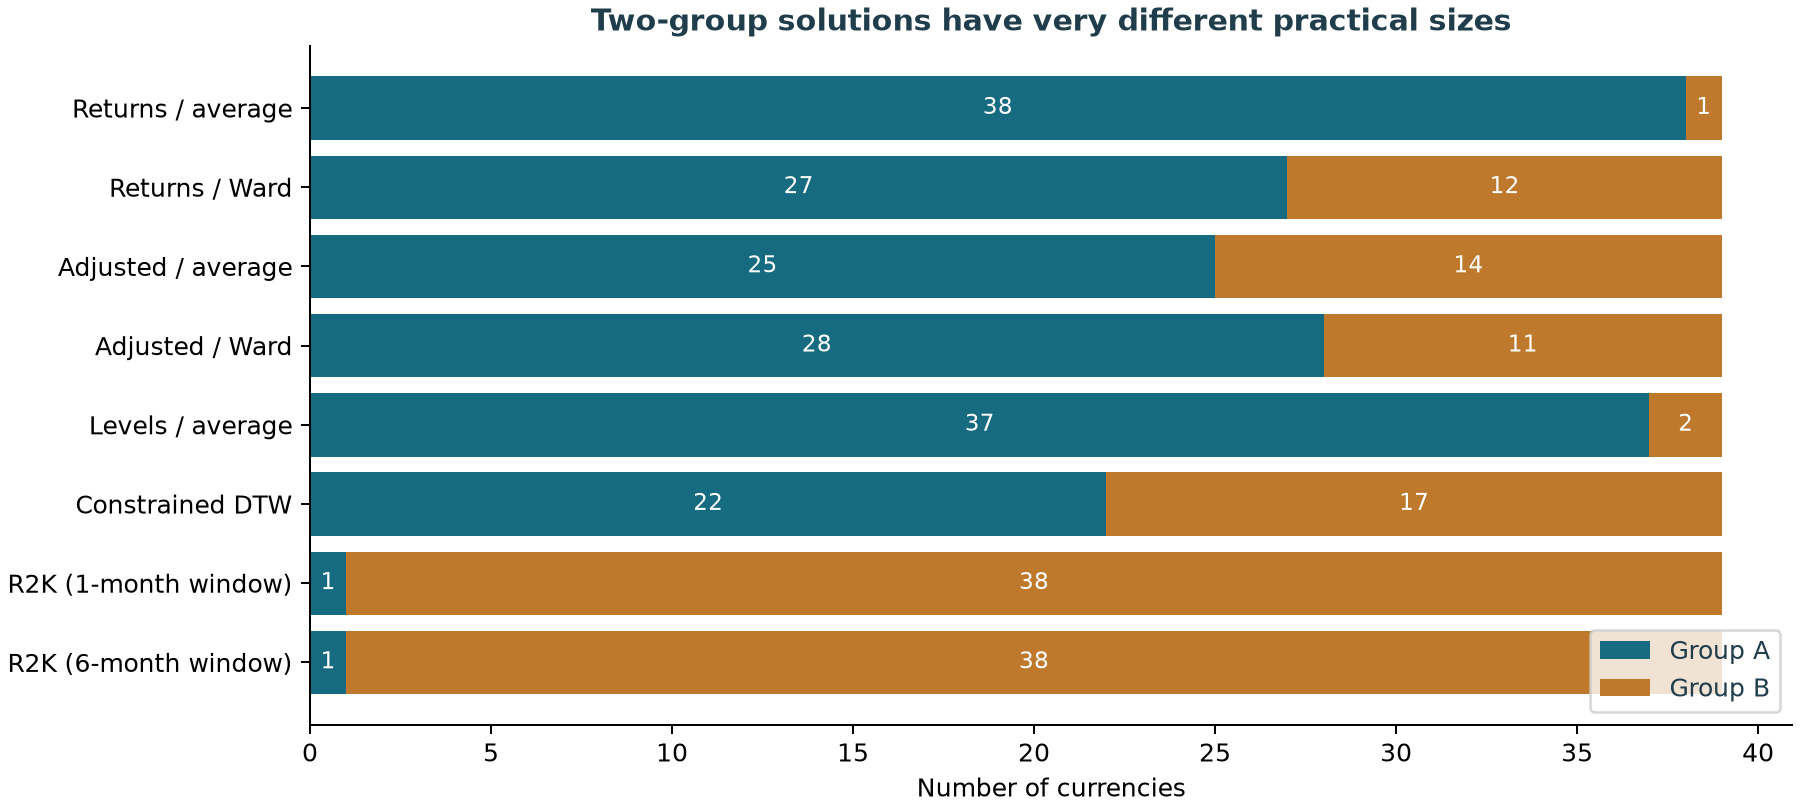

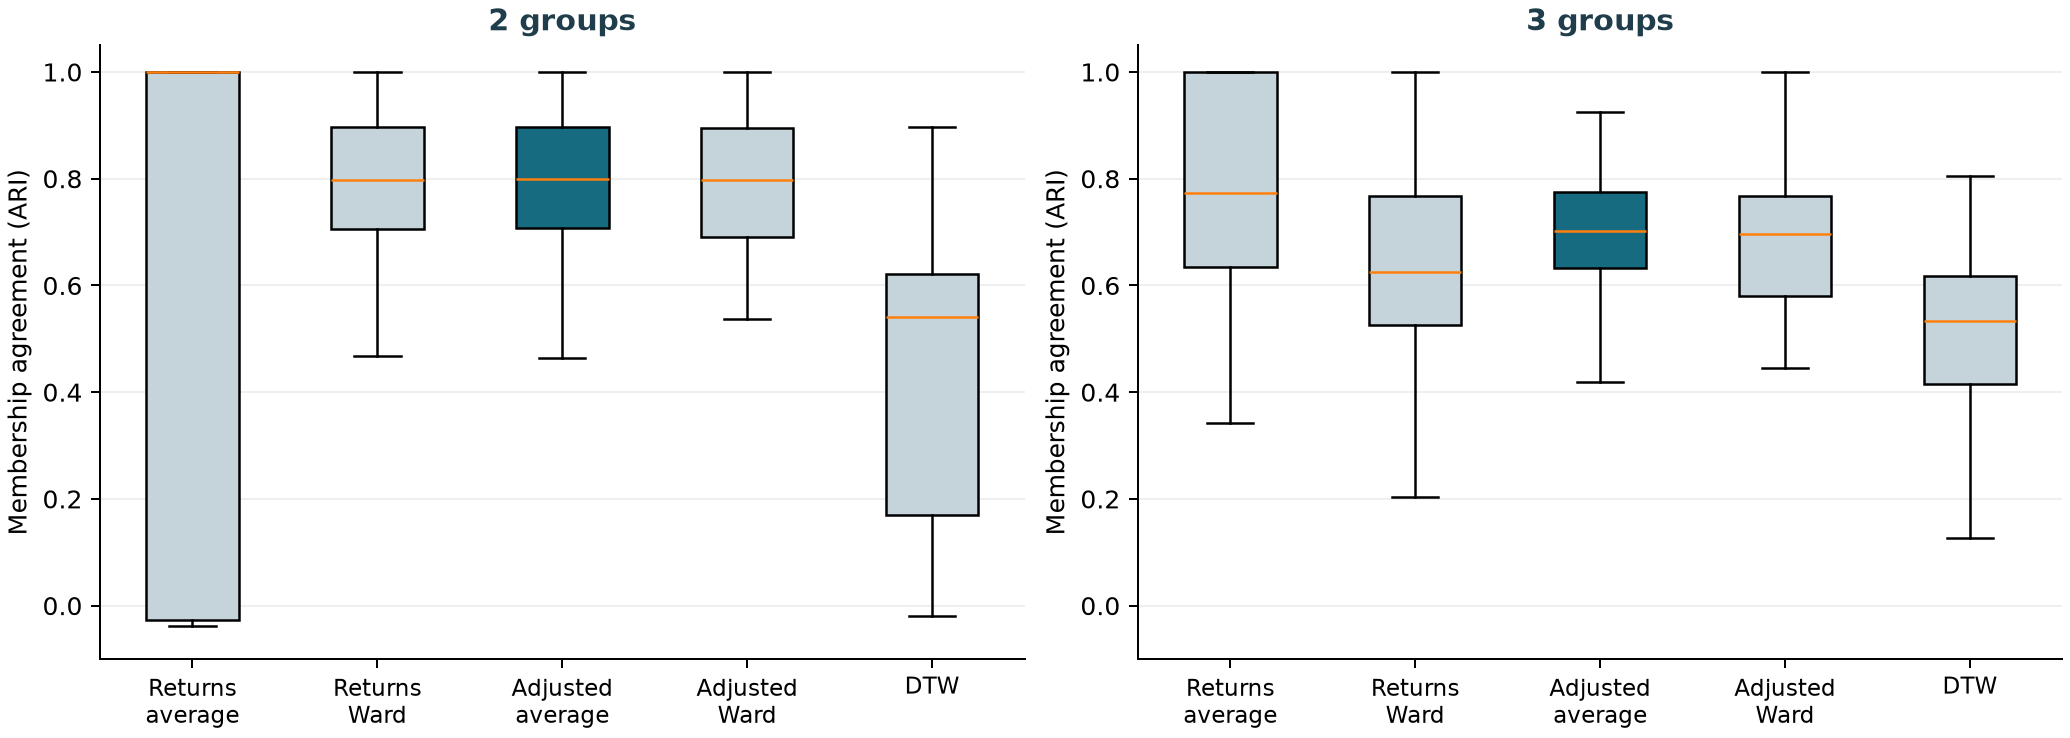

In [6]:
display(Image(filename=str(OUTPUT / "group_sizes.png")))
display(Image(filename=str(OUTPUT / "cluster_stability.png")))

## 2. Frozen candidate memberships

The K=2 adjusted-average candidate has 25 and 14 currencies; the K=3 alternative has 14, 14 and 11. Representatives are observed medoid currencies. Cluster numbers are categorical identifiers, not economic rankings or emerging/advanced classifications. The groups stay fixed for the later validation and test periods.

,k,cluster,representative,currencies,reporting_groups
0,2,0,SGD,"ARS, AUD, BRL, CAD, CLP, CNY, COP, DZD, IDR, I...","{'emerging_and_developing': 16, 'advanced': 9}"
1,2,1,EUR,"BAM, CHF, CZK, DKK, EUR, GBP, HUF, ISK, MAD, M...","{'emerging_and_developing': 7, 'advanced': 7}"


,k,cluster,representative,currencies,reporting_groups
0,3,0,ZAR,"ARS, AUD, BRL, CAD, CLP, COP, INR, KRW, MXN, N...","{'emerging_and_developing': 9, 'advanced': 5}"
1,3,1,EUR,"BAM, CHF, CZK, DKK, EUR, GBP, HUF, ISK, MAD, M...","{'emerging_and_developing': 7, 'advanced': 7}"
2,3,2,CNY,"CNY, DZD, IDR, ILS, JPY, MYR, PEN, PHP, SGD, T...","{'emerging_and_developing': 7, 'advanced': 4}"


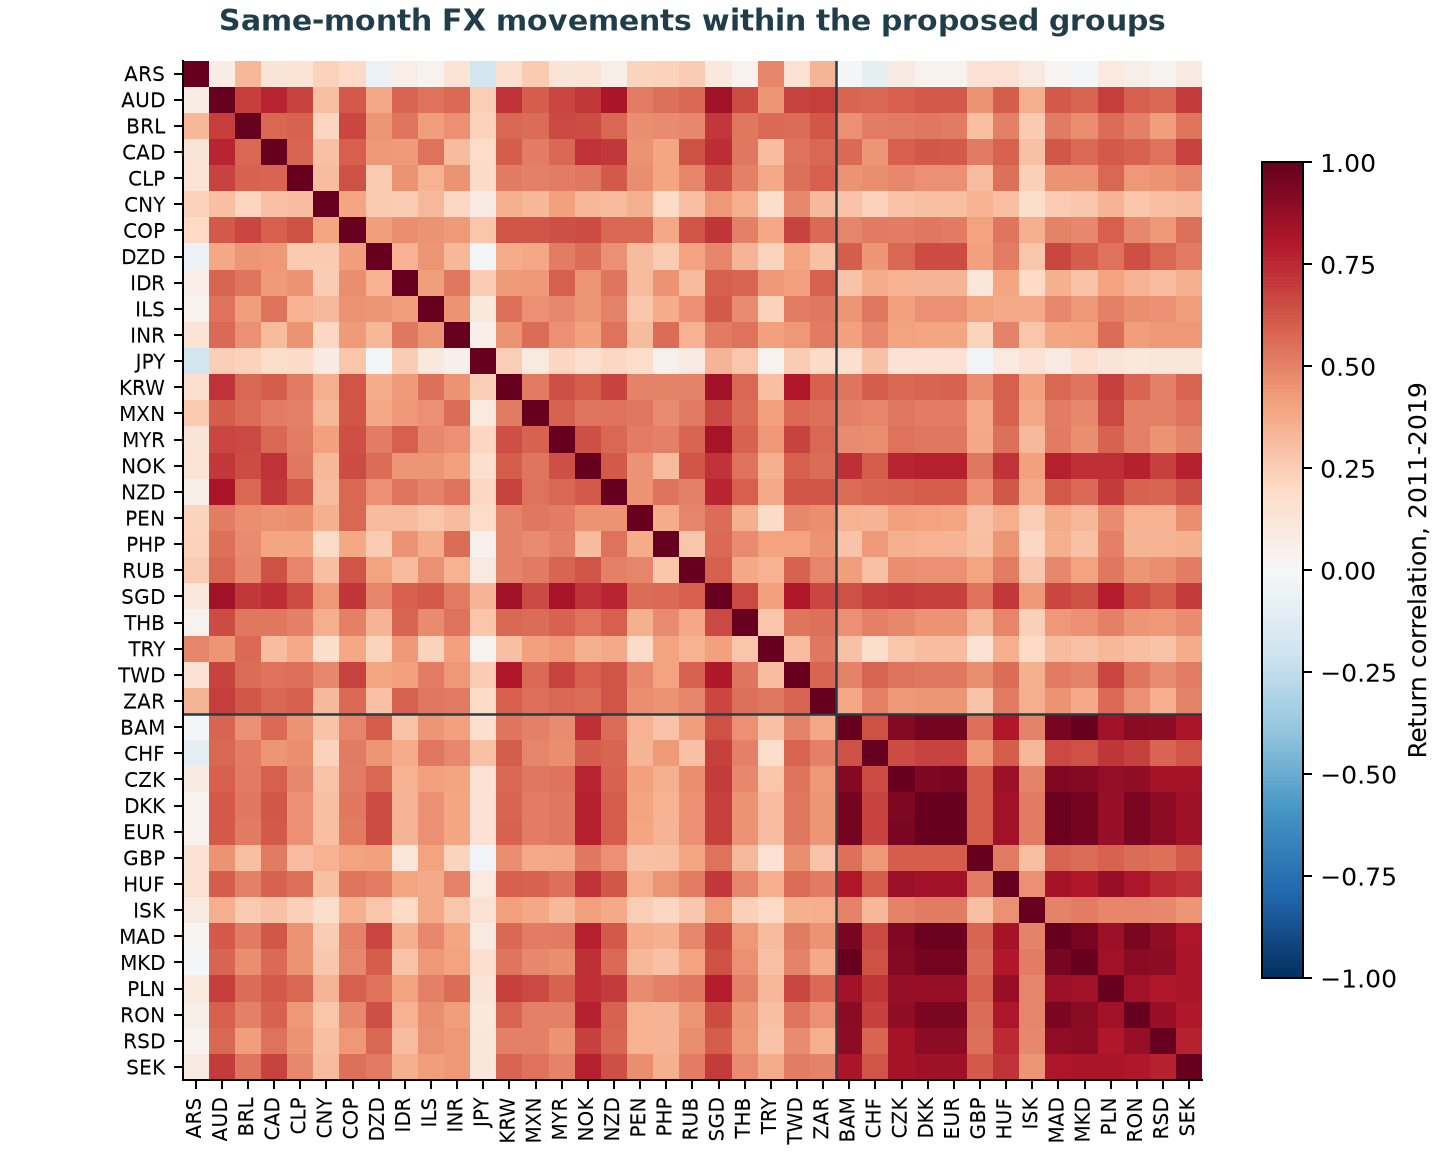

In [7]:
currency_meta = pd.read_csv(OUTPUT / "currency_metadata.csv").set_index("currency")
for k in (2, 3):
    table = []
    for group in groups[f"adjusted_average:k{k}"]["clusters"]:
        table.append({"k": k, "cluster": group["cluster"], "representative": group["representative"],
                      "currencies": ", ".join(group["currencies"]),
                      "reporting_groups": currency_meta.loc[group["currencies"], "group"].value_counts().to_dict()})
    display(pd.DataFrame(table))
display(Image(filename=str(OUTPUT / "group_correlations.png")))

## 3. All available BIS inputs, with causal timing

The canonical panel uses exact source IDs and the selected launch/peg exclusions. Positive log FX changes mean local-currency depreciation against USD. Local features are 1-, 3- and 12-month changes, twelve-month annualized monthly-return volatility, REER gap, policy differential and annual log-inflation differential. Global features are the lagged broad USD NEER change, log outside-US USD credit stock and annual credit growth.

REER and inflation use two-month reference lags; policy and USD NEER use one month. Credit uses the quarter containing the origin minus two. Policy and derived inflation allow only the first missing month to receive a flagged causal carry. FX/index/credit observations are not filled. Structural policy/CPI absence remains separate from temporary gaps. The monthly Parquet tables retain source/reference and carry provenance.

Training-only optional macro medians and per-feature scaling are shared by all groups. Mandatory missing inputs are masked placeholders. Statistics use monthly feature cells through the training cutoff, not only complete selected sequences. Targets retain original percent log-change units. These revised histories and retrospective regime exclusions do not reconstruct real-time vintages.

In [8]:
coverage = pd.read_csv(OUTPUT / "feature_coverage.csv")
display(coverage.pivot(index=["block", "feature"], columns="split", values="available_fraction").round(3))
meta = json.loads((OUTPUT / "dataset_metadata.json").read_text())
display(pd.DataFrame(meta["source_absent"]).T.query("policy or cpi"))

split                         test  train  validation
block  feature                                       
global usd_credit_log_stock  1.000  0.750       1.000
       usd_credit_yoy        1.000  0.712       1.000
       usd_neer_change       1.000  0.994       1.000
local  fx_change_12m         0.999  0.920       1.000
       fx_change_1m          0.999  0.957       1.000
       fx_change_3m          0.999  0.951       1.000
       inflation_diff        0.949  0.879       0.949
       rate_diff             0.890  0.796       0.897
       reer_gap              1.000  0.791       1.000
       volatility_12m        0.999  0.920       1.000

,policy,cpi
DZD,True,False
BAM,True,True
TWD,True,True
SGD,True,False


## 4. True sequence counts

The full array has one fixed 39-currency axis and 381 calendar origins; that is not 381 usable training examples for every cluster. Eligibility depends on the complete input history and target horizon. CNY exclusions and the 12-month feature/sequence warm-up particularly constrain the 25-currency group. The old 11,994 scalar currency/horizon rows were a different object and must not be described as independent multivariate samples.

The loader defaults to complete mandatory inputs, permits the documented optional macro imputation, and requires at least one observed target cell. Target masks handle missing currency outputs and horizon endpoints. `require_all_targets=True` provides a stricter complete-output option. Credit ablations must intersect samples because credit eligibility can remove additional early origins.

split                                              test  train  validation
cluster n_currencies view                 horizon                         
0       25           fx                   1          43     90          35
                                          3          41     88          33
                                          12         32     79          24
                     macro                1          43     90          35
                                          3          41     88          33
                                          12         32     79          24
                     macro_without_credit 1          43     90          35
                                          3          41     88          33
                                          12         32     79          24
1       14           fx                   1          43    228          35
                                          3          41    226          33
                                          12         32    217          24
                     macro                1          43    178          35
                                          3          41    176          33
                                          12         32    167          24
                     macro_without_credit 1          43    178          35
                                          3          41    176          33
                                          12         32    167          24

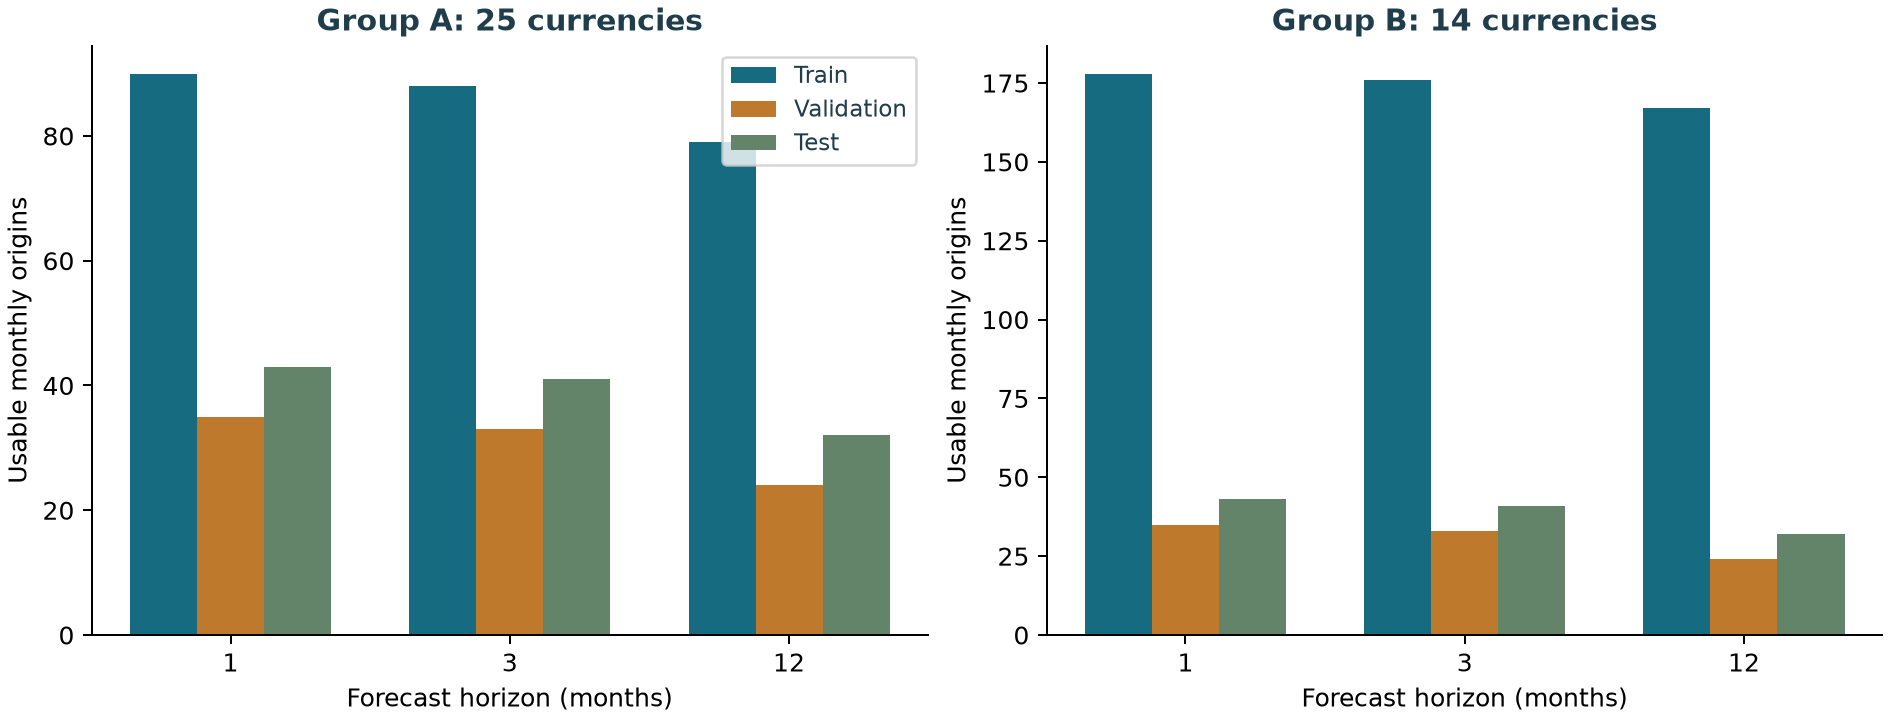

In [9]:
selected_counts = counts.loc[counts.method.eq("adjusted_average") & counts.k.eq(2)]
display(selected_counts.pivot(index=["cluster", "n_currencies", "view", "horizon"],
                              columns="split", values="usable_origins"))
display(Image(filename=str(OUTPUT / "sequence_counts.png")))

## 5. Coherence, stability and the theory of sharing

K=2–6 were all compared; K=2 is an operational default, not an inferred optimum. K=1 is the all-currency control. The 25-currency default group has average raw correlation 0.448 within versus 0.442 outside; the Europe-heavy group has 0.750 within. Stable membership does not guarantee internal coherence.

The new tables add per-group recovery in 50 twelve-month block resamples and 200 factor-preserving references at ranks 1 and 3. The latter retain fixed training PCA factors and independently shift residual histories. They are exploratory conditional reference ranges, not formal significance tests or augmented neural training data.

Same-month covariance need not imply cross-currency predictability. Inspect the [short findings brief](../reports/clustering/handoff/clustering_report.html#evidence) and PDF Appendices E–J for this distinction, the complete K profile, bootstrap coassignment, and hard versus soft sharing. Adjusted Ward K=4 is a larger-K challenger with no singleton, but its six-currency SGD group is weak. Neural validation must assess the forecasting restriction on matched origins and capacity budgets.

In [10]:
quality = pd.read_csv(OUTPUT / "group_quality.csv").merge(
    pd.read_csv(OUTPUT / "group_recovery.csv"),
    on=["method", "k", "cluster"], how="left",
)
display(quality.loc[
    (quality.method.eq("adjusted_average") & quality.k.isin([2, 3]))
    | (quality.method.eq("adjusted_ward") & quality.k.eq(4))
])
factor_reference = pd.read_csv(OUTPUT / "factor_reference.csv")
display(factor_reference.loc[
    factor_reference.method.eq("adjusted_average") & factor_reference.k.eq(2)
])

,method,k,cluster,n_currencies,representative,within_raw_correlation,outside_raw_correlation,mean_silhouette,negative_silhouettes,mean_jaccard,p10_jaccard,bootstrap_reps
0,adjusted_average,2,0,25,SGD,0.447596,0.441954,0.123612,1,0.912227,0.857143,50.0
1,adjusted_average,2,1,14,EUR,0.749643,0.441954,0.267526,0,0.856976,0.733333,50.0
2,adjusted_average,3,0,14,ZAR,0.501704,0.449858,0.079128,3,0.771180,0.620833,50.0
3,adjusted_average,3,1,14,EUR,0.749643,0.441954,0.236536,0,0.866108,0.780476,50.0
4,adjusted_average,3,2,11,CNY,0.406011,0.421494,0.187666,0,0.719355,0.596667,50.0
25,adjusted_ward,4,0,12,BRL,0.509939,0.448318,0.092295,1,0.714623,0.500000,50.0
26,adjusted_ward,4,1,11,EUR,0.877696,0.476301,0.359418,0,0.796297,0.636364,50.0
27,adjusted_ward,4,2,6,SGD,0.511745,0.488648,-0.038687,5,0.278770,0.198750,50.0
28,adjusted_ward,4,3,10,CNY,0.341726,0.398918,0.136149,0,0.688582,0.534615,50.0


,method,k,factor_rank,observed_silhouette,reference_p05,reference_median,reference_p95,reference_reps
10,adjusted_average,2,1,0.175273,0.088684,0.104527,0.118640,200
30,adjusted_average,2,3,0.175273,0.172428,0.186633,0.199036,200


## 6. A teammate-ready batch

The core shapes are `X_local[N,12,C,7]`, `X_global[N,12,3]`, `Y[N,C,H]` plus availability/carry and target masks. Group selection changes only the currency subset; channel identity and order remain fixed. FX-only selection exposes four local FX features and no globals. Macro selection exposes seven local features; `with_credit=False` retains only the USD NEER global channel.

Training origins extend through December 2019, validation through December 2022, and test through the data endpoint. Targets ending after each split cutoff are masked **and numerically zeroed**, even when the later snapshot contains the realized value. Prior observed months may supply validation/test input history.

In [11]:
batch = load_cluster_dataset(OUTPUT, method="adjusted_average", k=2, cluster=0,
                             split="train", horizon=3, feature_view="macro")
print("X_local", batch.X_local.shape, "X_global", batch.X_global.shape, "Y", batch.Y.shape)
print("Currency order:", batch.currencies)
print("Input features:", batch.local_features)
assert (batch.input_periods <= batch.origins[:, None]).all()
assert (batch.target_endpoints <= "2019-12").all()
# Interface demonstration only: substitute your network output for prediction.
prediction = np.zeros_like(batch.Y)
masked_mse = (((prediction - batch.Y)**2) * batch.Y_mask).sum() / batch.Y_mask.sum()
print("Observed target cells:", int(batch.Y_mask.sum()), "| illustrative masked loss:", float(masked_mse))

X_local (88, 12, 25, 7) X_global (88, 12, 3) Y (88, 25, 1)
Currency order: ('ARS', 'AUD', 'BRL', 'CAD', 'CLP', 'CNY', 'COP', 'DZD', 'IDR', 'ILS', 'INR', 'JPY', 'KRW', 'MXN', 'MYR', 'NOK', 'NZD', 'PEN', 'PHP', 'RUB', 'SGD', 'THB', 'TRY', 'TWD', 'ZAR')
Input features: ('fx_change_1m', 'fx_change_3m', 'fx_change_12m', 'volatility_12m', 'reer_gap', 'rate_diff', 'inflation_diff')
Observed target cells: 2200 | illustrative masked loss: 33.821853693181815


In [12]:
# Same numerical bundle, different frozen channel selection.
alternative = load_cluster_dataset(OUTPUT, method="adjusted_average", k=3, cluster=0,
                                   split="validation", horizon=12)
global_control = load_cluster_dataset(OUTPUT, method="all", k=1, cluster=0,
                                      split="validation", horizon=12)
print("K=3 alternative:", alternative.X_local.shape, "| all-currency control:", global_control.X_local.shape)
# complete_inputs=False is available for an explicitly mask-aware architecture;
# its placeholders must never be treated as observed economic values.

K=3 alternative: (24, 12, 14, 7) | all-currency control: (24, 12, 39, 7)


## 7. Review findings, corrections and next modeling work

Three independent subagent reviews covered methodology/data, code correctness/bloat, and alignment/handoff. Their main correction was the distinction between separate scalar row routing and synchronized vector forecasting. The scalar Ridge audit remains optional and cannot reject the current use case.

A frozen grouping fitted entirely within training can assign that whole training history before later evaluation. Dynamic monthly regime descriptors need causal states and must not replace currency channels. The R2K reference remains available in notebook 04. Confirmed bugs in convergence checks, fixed-scaling coordinates and stale-output provenance were corrected and regression-tested.

The required workflow is one builder/loader and report. No neural trainer, new scalar forecasting screen or generic experimentation framework is introduced. Teammates should compare candidate clusters, K=3 and the all-currency control on matched data, using model capacity appropriate to the small number of independent time origins. Shared shocks, overlapping windows, revised histories and previously inspected data limit inference. No neural forecasting performance has been claimed.

Run `python -m pytest -q` for temporal invariance, masks, data lags/carries, fixed-axis/export checks and reviewed regressions.

Read the generated [Markdown report](../reports/clustering/handoff/clustering_report.md) or [PDF report](../reports/clustering/handoff/clustering_report.pdf). Method references and exact versions/hashes are included there and in the manifest.